
# Task 3: Object Recognition using Viola–Jones and YOLO

## Objective
To perform object detection using two computer vision approaches: the Viola–Jones method with a pretrained Haar Cascade classifier and the YOLO object detection model.

## Methods
1. Face detection using Haar Cascade.
2. Object detection using a pretrained YOLO model.
3. Visualization of detected objects using bounding boxes and labels.
4. Comparison of the detection results from both methods.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("OpenCV version:", cv2.__version__)
print("Libraries imported successfully!")

OpenCV version: 4.10.0
Libraries imported successfully!


In [2]:
os.makedirs("outputs", exist_ok=True)

print(
    "Face photo exists:",
    os.path.exists("task3_images/face.jpg")
)

print(
    "Objects photo exists:",
    os.path.exists("task3_images/objects.jpg")
)

Face photo exists: True
Objects photo exists: True


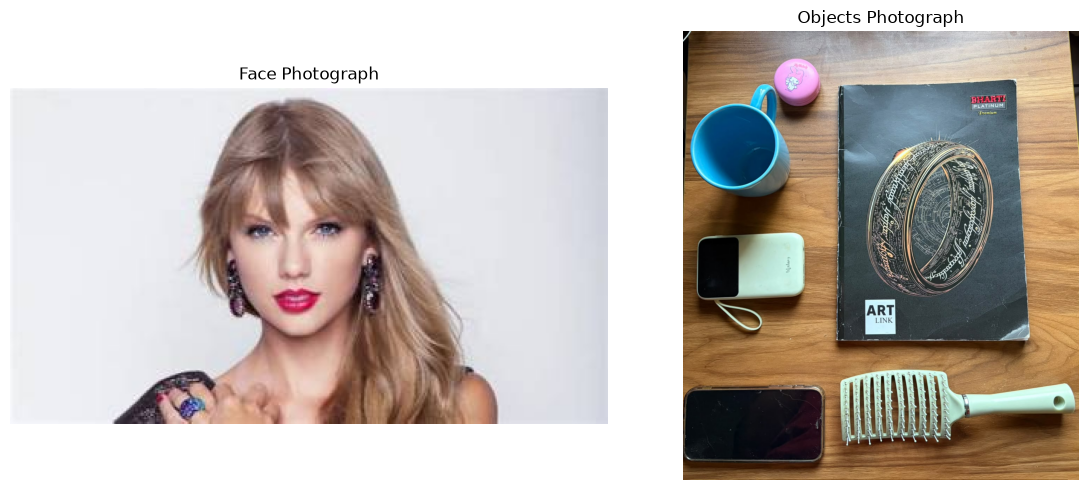

Both photographs loaded successfully!


In [3]:
# Load the face photograph
face_bgr = cv2.imread("task3_images/face.jpg")

# Load the objects photograph
objects_bgr = cv2.imread("task3_images/objects.jpg")

# Convert BGR to RGB for correct display
face_image = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)
objects_image = cv2.cvtColor(objects_bgr, cv2.COLOR_BGR2RGB)

# Display both photographs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(face_image)
plt.title("Face Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(objects_image)
plt.title("Objects Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Both photographs loaded successfully!")

In [4]:
# Load OpenCV's pretrained face detector
cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(cascade_path)

# Convert the face photograph to grayscale
face_gray = cv2.cvtColor(face_image, cv2.COLOR_RGB2GRAY)

# Detect faces
faces = face_cascade.detectMultiScale(
    face_gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of faces detected:", len(faces))

Number of faces detected: 1


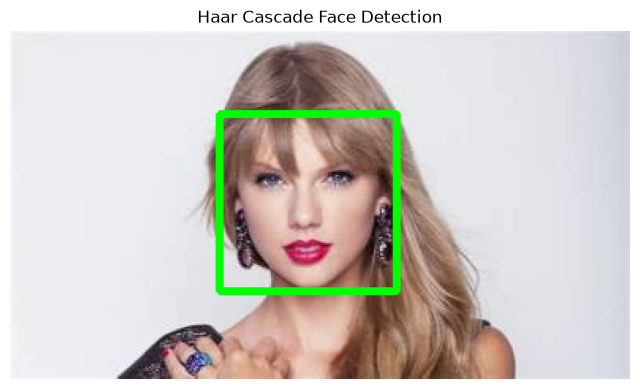

Face detection result saved!


In [5]:
# Make a copy so the original image remains unchanged
face_result = face_image.copy()

# Draw a rectangle around each detected face
for (x, y, w, h) in faces:
    cv2.rectangle(
        face_result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Display the result
plt.figure(figsize=(8, 6))
plt.imshow(face_result)
plt.title("Haar Cascade Face Detection")
plt.axis("off")
plt.show()

# Save the result
cv2.imwrite(
    "outputs/haar_face_detection.jpg",
    cv2.cvtColor(face_result, cv2.COLOR_RGB2BGR)
)

print("Face detection result saved!")

Faces detected: 2


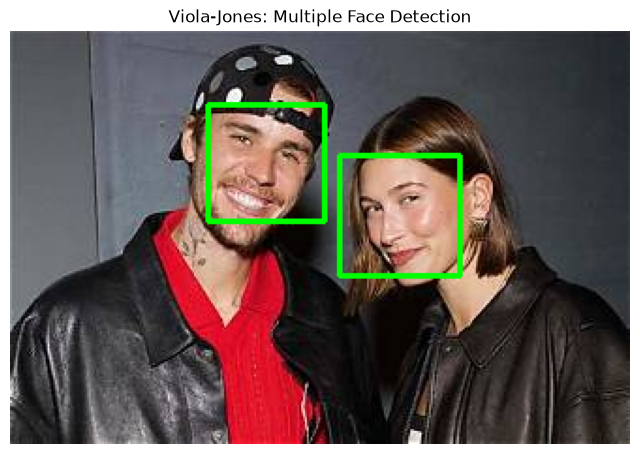

In [6]:
# Load the image containing multiple faces
multiple_image = cv2.imread("task3_images/multiple_faces.jpg")

if multiple_image is None:
    print("Error: Could not load multiple_faces.jpg")
else:
    # Convert the image to grayscale
    multiple_gray = cv2.cvtColor(
        multiple_image, cv2.COLOR_BGR2GRAY
    )

    # Detect faces with more sensitive settings
    multiple_faces = face_cascade.detectMultiScale(
        multiple_gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(20, 20)
    )

    print("Faces detected:", len(multiple_faces))

    # Draw rectangles around detected faces
    result_image = multiple_image.copy()

    for (x, y, w, h) in multiple_faces:
        cv2.rectangle(
            result_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    # Display the result
    plt.figure(figsize=(8, 6))
    plt.imshow(
        cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)
    )
    plt.title("Viola-Jones: Multiple Face Detection")
    plt.axis("off")
    plt.show()

    # Save the result
    cv2.imwrite(
        "outputs/haar_multiple_faces_adjusted.jpg",
        result_image
    )

In [7]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\ProgramData\anaconda3\python.exe
Python version: 3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]


In [8]:
%pip install --force-reinstall torch==2.8.0 torchvision==0.23.0

Defaulting to user installation because normal site-packages is not writeable
  Using cached torch-2.8.0-cp311-cp311-win_amd64.whl.metadata (30 kB)
  Using cached torchvision-0.23.0-cp311-cp311-win_amd64.whl.metadata (6.1 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp311-cp311-win_amd64.whl.metadata (2.8 kB)
Using cached torch-2.8.0-cp311-cp311-win_amd64.whl (241.4 MB)
Using cached torchvision-0.23.0-cp

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
astropy 5.3.4 requires numpy<2,>=1.21, but you have numpy 2.4.6 which is incompatible.
numba 0.59.0 requires numpy<1.27,>=1.22, but you have numpy 2.4.6 which is incompatible.
pywavelets 1.5.0 requires numpy<2.0,>=1.22.4, but you have numpy 2.4.6 which is incompatible.
s3fs 2023.10.0 requires fsspec==20

In [9]:
import torch
print(torch.__version__)

2.8.0+cpu


In [10]:
from ultralytics import YOLO
print("YOLO is ready!")

YOLO is ready!


In [11]:
import torch
print("PyTorch version:", torch.__version__)
print("PyTorch is working!")

PyTorch version: 2.8.0+cpu
PyTorch is working!


In [12]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [13]:
import cv2
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!



image 1/1 C:\Users\bangt\CCA3_Computer_Vision\task3_images\objects.jpg: 640x576 1 cup, 1 mouse, 1 cell phone, 1 book, 1 clock, 1 toothbrush, 99.1ms
Speed: 6.5ms preprocess, 99.1ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 576)


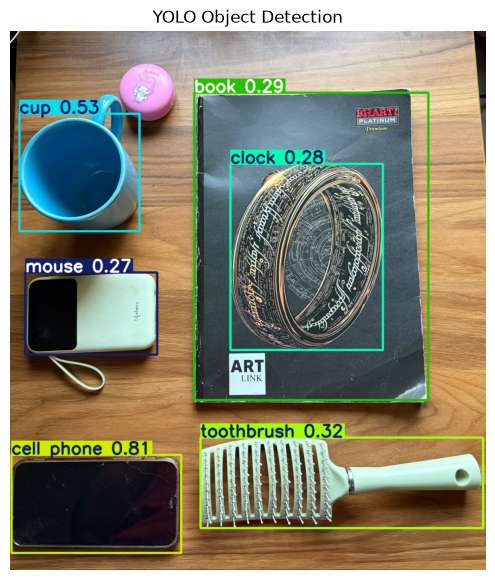

Output saved successfully!


In [14]:
# Run YOLO on the objects image
results = model("task3_images/objects.jpg")

# Get the image with bounding boxes and labels
annotated_image = results[0].plot()

# Convert BGR to RGB for displaying in matplotlib
annotated_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

# Display the detected objects
plt.figure(figsize=(10, 7))
plt.imshow(annotated_rgb)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

# Save the output image
cv2.imwrite("outputs/yolo_object_detection.jpg", annotated_image)

print("Output saved successfully!")

In [15]:
# Print the object names and confidence scores
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    object_name = model.names[class_id]

    print(
        "Detected object:", object_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )

Detected object: cell phone | Confidence: 80.78 %
Detected object: cup | Confidence: 52.76 %
Detected object: toothbrush | Confidence: 31.73 %
Detected object: book | Confidence: 29.27 %
Detected object: clock | Confidence: 28.2 %
Detected object: mouse | Confidence: 26.68 %


Detected object: cell phone | Confidence: 80.78 %
Detected object: cup | Confidence: 52.76 %
Detected object: toothbrush | Confidence: 31.73 %
Detected object: book | Confidence: 29.27 %
Detected object: clock | Confidence: 28.2 %
Detected object: mouse | Confidence: 26.68 %

## Comparison of Viola–Jones and YOLO

| Feature | Viola–Jones (Haar Cascade) | YOLO |
|---|---|---|
| Main purpose | Face detection in this experiment | Detection of multiple object classes |
| Method | Uses Haar-like features and a cascade classifier | Uses a pretrained deep-learning model |
| Output | Face bounding boxes | Object bounding boxes, class labels, and confidence scores |
| Strength | Simple and relatively fast for frontal faces | Can detect several object categories in one image |
| Limitation | May miss faces because of angle, size, or lighting | May misclassify unfamiliar or visually similar objects |

### Conclusion

In this experiment, Viola–Jones was used to detect faces, while YOLO was used to detect everyday objects. Haar Cascade successfully detected a face in the test image, although it missed one face in the multiple-face image. YOLO detected six objects but incorrectly classified some of them.

Both approaches are useful for object detection, but their performance depends on the input image and the capabilities of the detector. YOLO provides more general object recognition, whereas the Haar Cascade used here is specialized for face detection.